# Practical 1: Uber Fare Prediction
**Aim:** Predict Uber fare using Linear Regression and Random Forest Regression.

**Dataset:** Keep `uber.csv` in the same folder as this notebook.

### Short Theory
Uber fare prediction is a **regression problem** because the fare is a continuous numerical value. We use pickup and drop-off locations, passenger count and pickup time as input features. Linear Regression and Random Forest Regression are trained to predict the fare. Their performance is compared using R², RMSE and MAE.

### Theory
We import Pandas and NumPy for data handling, Matplotlib and Seaborn for graphs, and Scikit-learn for training and evaluating the models.

In [15]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

### Theory
The dataset is loaded from the CSV file using Pandas. `head()` displays the first five rows to understand the data.

In [17]:
# 2. Read dataset
df = pd.read_csv("uber_fares_dataset.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


### Theory
Preprocessing removes unnecessary columns and missing values. We also convert pickup time into date-time format and create useful time-based features.

In [18]:
# 3. Preprocess data
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")
df = df.dropna()

df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce")
df = df.dropna()

df = df[(df["fare_amount"] > 0) & (df["passenger_count"] > 0)]

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month

print("Dataset shape:", df.shape)

Dataset shape: (199269, 10)


### Theory
Outliers are unusually high or low values. The IQR method helps identify and remove fare values outside the normal range.

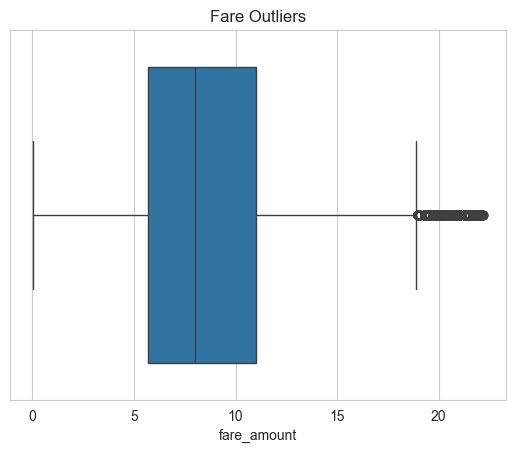

In [19]:
# 4. Identify and remove outliers using IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

df = df[(df["fare_amount"] >= Q1 - 1.5 * IQR) &
        (df["fare_amount"] <= Q3 + 1.5 * IQR)]

sns.boxplot(x=df["fare_amount"])
plt.title("Fare Outliers")
plt.show()

### Theory
Correlation shows how strongly numerical features are related. A heatmap makes these relationships easy to understand.

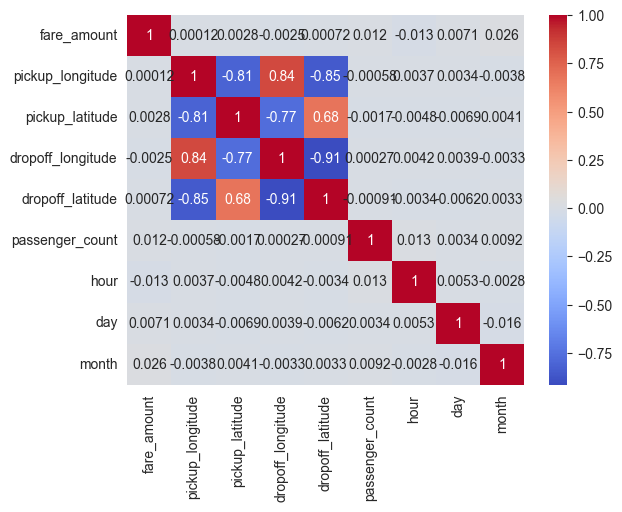

In [20]:
# 5. Check correlation
cols = ["fare_amount", "pickup_longitude", "pickup_latitude",
        "dropoff_longitude", "dropoff_latitude", "passenger_count",
        "hour", "day", "month"]

sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm")
plt.show()

### Theory
The dataset is divided into training data and testing data. The model learns from training data and is evaluated using testing data.

In [22]:
# 6. Split data into training and testing sets
X = df[["pickup_longitude", "pickup_latitude",
        "dropoff_longitude", "dropoff_latitude",
        "passenger_count", "hour", "day", "month"]]
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### Theory
Linear Regression predicts a continuous value by learning the relationship between input features and the fare amount.

In [23]:
# 7. Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

print("Linear Regression")
print("R2:", r2_score(y_test, pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_lr)))
print("MAE:", mean_absolute_error(y_test, pred_lr))

Linear Regression
R2: 0.0013134180011107333
RMSE: 4.12679317106973
MAE: 3.281215477195282


### Theory
Random Forest uses multiple decision trees and combines their predictions to estimate the fare amount.

In [25]:
# 8. Random Forest Regression
rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print("Random Forest")
print("R2:", r2_score(y_test, pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_rf)))
print("MAE:", mean_absolute_error(y_test, pred_rf))

Random Forest
R2: 0.7149918622891664
RMSE: 2.204584379780569
MAE: 1.5400946951476253


## Result / Conclusion
Uber fare prediction was performed using Linear Regression and Random Forest Regression. The models were compared using R2, RMSE and MAE.

**Remember:** Higher R2 and lower RMSE/MAE indicate better performance.